# Conditions in Python

A program must often make decisions: approve or reject, warn or continue. **Conditional statements** run different code for different situations.

**After this lesson you can:**

1. Write `if`, `elif` and `else` blocks.
2. Combine conditions with `and`, `or`, `not`.
3. Explain truthiness and short-circuit evaluation.
4. Use the conditional expression `a if condition else b`.

## 1. `if`, `elif`, `else`

Python checks the conditions from top to bottom. It runs the **first** block whose condition is true and skips the rest. Indentation (4 spaces) marks the block.

```python
if condition_1:
    ...            # runs when condition_1 is true
elif condition_2:
    ...            # runs when condition_1 is false and condition_2 is true
else:
    ...            # runs when all conditions are false
```

In [1]:
def grade(score: float) -> str:
    if score >= 90:
        return "A"
    elif score >= 80:
        return "B"
    elif score >= 70:
        return "C"
    elif score >= 60:
        return "D"
    else:
        return "F"

for s in [95, 83, 70, 61.5, 42]:
    print(f"score {s:>5} -> {grade(s)}")

score    95 -> A
score    83 -> B
score    70 -> C
score  61.5 -> D
score    42 -> F


The order of the conditions is important. A score of 95 also satisfies `score >= 80`, but Python stops at the first true condition (`>= 90`).

## 2. Comparison and Logical Operators

| Operator | Meaning |
| :--- | :--- |
| `==`, `!=` | equal, not equal |
| `<`, `<=`, `>`, `>=` | ordering; can be chained: `0 <= x < 10` |
| `in`, `not in` | membership |
| `is`, `is not` | same object (use for `None`) |
| `and`, `or`, `not` | logical combination |

In [2]:
age, has_ticket, country = 17, True, "TR"

print("Chained comparison 13 <= age < 18 :", 13 <= age < 18)
print("Can enter (age >= 18 and ticket)  :", age >= 18 and has_ticket)
print("Discount (age < 18 or age >= 65)  :", age < 18 or age >= 65)
print("EU visitor?                       :", country in {"DE", "FR", "NL"})
value = None
print("value is None                     :", value is None)

Chained comparison 13 <= age < 18 : True
Can enter (age >= 18 and ticket)  : False
Discount (age < 18 or age >= 65)  : True
EU visitor?                       : False
value is None                     : True


## 3. Truthiness and Short-Circuit Evaluation

Every object has a truth value. These values are **falsy**: `False`, `None`, `0`, `0.0`, `""`, `[]`, `{}`, `set()`. All other values are **truthy**.

`and` and `or` use **short-circuit evaluation**: Python stops as soon as the result is known.

- `a and b`: if `a` is falsy, Python returns `a` and does not evaluate `b`.
- `a or b`: if `a` is truthy, Python returns `a` and does not evaluate `b`.

This prevents errors, for example a division by zero.

In [3]:
for v in [0, 1, "", "text", [], [0], None, {}]:
    print(f"{v!r:<8} -> {'truthy' if v else 'falsy'}")

orders = []
average = len(orders) and sum(orders) / len(orders)     # no ZeroDivisionError: stops at len(orders) == 0
print("\nAverage of empty orders:", average)

username = "" or "guest"                                  # common default pattern
print("Username:", username)

0        -> falsy
1        -> truthy
''       -> falsy
'text'   -> truthy
[]       -> falsy
[0]      -> truthy
None     -> falsy
{}       -> falsy

Average of empty orders: 0
Username: guest


## 4. Conditional Expression and `match`

A **conditional expression** selects one of two values in one line:

```python
label = "even" if n % 2 == 0 else "odd"
```

For many cases that compare one value, Python 3.10+ has the `match` statement. Lesson 18 explains `match` in detail.

In [4]:
for n in range(1, 6):
    label = "even" if n % 2 == 0 else "odd"
    print(n, label)

def http_status(code: int) -> str:
    match code:
        case 200 | 201:
            return "success"
        case 404:
            return "not found"
        case c if 500 <= c < 600:
            return "server error"
        case _:
            return "other"

print([http_status(c) for c in (200, 404, 503, 302)])

1 odd
2 even
3 odd
4 even
5 odd
['success', 'not found', 'server error', 'other']


## 5. Visualising a Decision Rule

Conditions split the input space into regions. The plot applies the `grade()` function to 300 exam scores. The scores come from a normal distribution with mean 72 and standard deviation 12 (synthetic data).

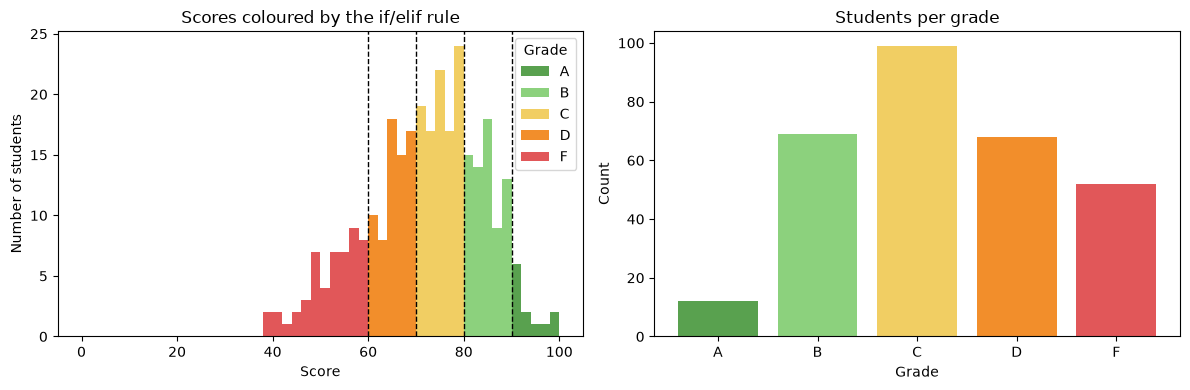

{'A': 12, 'B': 69, 'C': 99, 'D': 68, 'F': 52}


In [5]:
import random
from collections import Counter

import matplotlib.pyplot as plt

random.seed(7)
scores = [min(100, max(0, random.gauss(72, 12))) for _ in range(300)]
grades = [grade(s) for s in scores]
counts = Counter(grades)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
colors = {"A": "#59A14F", "B": "#8CD17D", "C": "#F1CE63", "D": "#F28E2B", "F": "#E15759"}
for g in "ABCDF":
    ax1.hist([s for s, gr in zip(scores, grades) if gr == g], bins=range(0, 101, 2), color=colors[g], label=g)
for t in (60, 70, 80, 90):
    ax1.axvline(t, color="black", lw=1, ls="--")
ax1.set(title="Scores coloured by the if/elif rule", xlabel="Score", ylabel="Number of students")
ax1.legend(title="Grade")
ax2.bar(list("ABCDF"), [counts[g] for g in "ABCDF"], color=[colors[g] for g in "ABCDF"])
ax2.set(title="Students per grade", xlabel="Grade", ylabel="Count")
plt.tight_layout()
plt.show()
print({g: counts[g] for g in "ABCDF"})

*Insight: Put the most specific or the strictest condition first. In an `if/elif` chain, the first true condition wins, so a wrong order silently gives wrong results instead of an error.*

## Real-World Use Case or Analogy

Conditions are like **a traffic police officer at a junction**. The officer checks the situation in a fixed sequence: Is an ambulance coming? Is the light red? Is the road clear? The first rule that applies decides the action.

Credit-card fraud systems start with simple rules of the same form: *if* the amount is more than 10 times the customer's average *and* the country is new *then* hold the payment. Later, machine-learning models (M16) replace many hand-written rules, but the final decision is still an `if` on the model score.